In [1]:
import pandas as pd
from zoneinfo import ZoneInfo
from datetime import datetime as dt, timezone
import holidays
import seaborn as sns
import json

In [2]:
stations_df = pd.read_csv('citibike-stations.csv')
id_to_shortname = dict(zip(stations_df['station_id'], stations_df['short_name']))
id_to_lat = dict(zip(stations_df['station_id'], stations_df['lat']))
id_to_lon = dict(zip(stations_df['station_id'], stations_df['lon']))
id_to_name = dict(zip(stations_df['station_id'], stations_df['name']))
shortname_to_name = dict(zip(stations_df['short_name'], stations_df['name']))

In [45]:
stations_df.head()

,capacity,eightd_has_key_dispenser,electric_bike_surcharge_waiver,external_id,has_kiosk,lat,lon,name,region_id,rental_methods,rental_url,short_name,station_id
0,66,True,False,66db5fae-0aca-11e7-82f6-3863bb44ef7c,True,40.764397,-73.973715,Grand Army Plaza & Central Park S,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6839.1,281
1,33,True,False,66db6da2-0aca-11e7-82f6-3863bb44ef7c,True,40.704633,-74.013617,Broadway & Battery Pl,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,4962.01,304
2,64,False,False,66dbc982-0aca-11e7-82f6-3863bb44ef7c,True,40.755103,-73.974987,E 47 St & Park Ave,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6584.12,359
3,45,False,False,66dbe441-0aca-11e7-82f6-3863bb44ef7c,True,40.722438,-74.005664,6 Ave & Canal St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5500.07,377
4,36,False,False,66dbe601-0aca-11e7-82f6-3863bb44ef7c,True,40.734927,-73.992005,University Pl & E 14 St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5905.11,382


In [23]:
used_shortname_to_name = {name: shortname_to_name[name] for name in df['shortname'].unique()}
used_shortname_to_name 

{'JC056': 'Sip Ave',
 '6650.07': 'E 55 St & 2 Ave',
 '5288.08': 'Park Pl & Church St',
 '3996.04': '2 Ave & 9 St',
 'JC099': 'Montgomery St',
 '7538.12': 'Central Park West & W 100 St',
 '4965.01': 'Lorimer St & Broadway',
 '7634.01': 'W 106 St & Amsterdam Ave',
 '5532.01': 'Mercer St & Spring St',
 '6215.04': 'W 25 St & 6 Ave',
 '6729.02': '21 St & 36 Ave',
 'JC013': 'Marin Light Rail',
 '4846.01': 'South St & Whitehall St',
 '5785.05': 'Greenpoint Ave & Manhattan Ave',
 '3978.13': 'Garfield Pl & 8 Ave',
 '4266.03': 'Clinton St & Union St',
 '5279.03': 'Centre St & Worth St',
 '6879.04': '28 Ave & 44 St',
 'JC084': 'Communipaw & Berry Lane',
 '6806.06': '35 Ave & 10 St',
 '6030.04': 'W 13 St & 7 Ave',
 'JC057': 'Riverview Park',
 '4962.01': 'Broadway & Battery Pl',
 '4488.08': 'Court St & State St',
 '6737.03': '36 Ave & 10 St',
 '4322.02': 'Dean St & 4 Ave'}

## Data Processing again bru

In [24]:
df = pd.read_csv('small_train_set.csv')

### Final Pipeline

In [15]:
df_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'IsRushHour','timestamp','minute']

def add_features(df):
    df['timestamp'] = pd.to_datetime(df['station_status_last_reported'], format="%Y-%m-%d %H:%M:%S%z", utc=True)
    df = df.drop('station_status_last_reported', axis=1)

    df['Month'] = df['timestamp'].dt.month
    df['Day'] = df['timestamp'].dt.dayofweek
    df['Hour'] = df['timestamp'].dt.hour
    df['IsWeekend'] = df['Day'].isin([5,6]).astype(int)
    df['lat'] = df['station_id'].map(id_to_lat)
    df['lon'] = df['station_id'].map(id_to_lon)
    df['minute'] = df['timestamp'].dt.minute
    df['percentage_available'] = df['num_bikes_available'] / (df['num_bikes_available'] + df['num_docks_available'])
    df['IsRushHour'] = ((df['Hour'].isin([7,8,9,16,17,18])) & (df['IsWeekend'] == 0)).astype(int)
    df['shortname'] = df['station_id'].map(id_to_shortname)


    ny_holidays = holidays.US(state='NY')
    holiday_date_list = list(ny_holidays.keys())

    df['IsHoliday'] = df['timestamp'].dt.date.isin(holiday_date_list).astype(int)
    df['IsNonWorkingDay'] = ((df['IsWeekend'] == 1) | (df['IsHoliday'] == 1)).astype(int)

    # hourly_variances = df.groupby(['station_id', 'Hour'])['percentage_available'].var()
    # station_volatility = hourly_variances.groupby(level=0).mean()
    # df['Volatility'] = df['station_id'].map(station_volatility)


    # lag features

    # df = df.sort_values('timestamp').reset_index(drop=True)
    # df['prev_percentage'] = df.groupby('station_id')['percentage_available'].shift(1)
    # df['time_since_last_lag'] = df.groupby('station_id')['timestamp'].diff().dt.total_seconds() / 60
    # df['time_since_last_lag'] = df['time_since_last_lag'].clip(upper=1440)
    # df['time_since_last_lag'] = df['time_since_last_lag'].fillna(0)

    return df

def process_file(csv_file):
    df = pd.read_csv(csv_file)

    df = add_features(df)


    print(f"Before dropping NA: {df.shape[0]} rows")
    df = df[df_columns + ['percentage_available']].dropna()
    print(f"After dropping NA: {df.shape[0]} rows")
    df['shortname'] = df['shortname'].astype('category')

    

    return df
    

In [53]:
og = pd.read_csv('small_train_set.csv')
og[og['station_id'] == 4537]

,station_id,num_bikes_available,num_docks_available,station_status_last_reported


### testing autocorr feature

In [ ]:
def add_vol(df):

    hourly_variances = df.groupby(['station_id', 'Hour'])['percentage_available'].var()
    station_volatility = hourly_variances.groupby(level=0).mean()
    df['Volatility'] = df['station_id'].map(station_volatility)
    return df;

## Baseline XgBoost

In [4]:
# Import necessary libraries for time series modeling
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor


In [24]:
df = process_file('mediumset_14thstbelow.csv')
feature_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'IsRushHour','minute']


X_train = df[feature_columns]
y_train = df['percentage_available']

Before dropping NA: 1445829 rows
After dropping NA: 1444660 rows


In [17]:
val_dataset = process_file('valset_14thstbelow.csv')
X_val = val_dataset[feature_columns]
y_val = val_dataset['percentage_available']

Before dropping NA: 29424 rows
After dropping NA: 29393 rows


### Base Line Model Training

In [ ]:
# Train baseline XGBoost model
print("Training baseline XGBoost model...")

# Initialize XGBoost regressor with default parameters
baseline_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.1,
    depth=6,
    loss_function='RMSE',
    eval_metric='RMSE',
    random_seed=42,
    verbose=100
)

baseline_model.fit(X_train, y_train, cat_features=['shortname', 'Month','Day'], eval_set=(X_val, y_val))

y_train_pred = baseline_model.predict(X_train)
y_val_pred = baseline_model.predict(X_val)

train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

val_mae = mean_absolute_error(y_val, y_val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
val_r2 = r2_score(y_val, y_val_pred)

print("\n=== Baseline Model Performance ===")
print(f"\nTraining Set:")
print(f"  MAE:  {train_mae:.4f}")
print(f"  RMSE: {train_rmse:.4f}")
print(f"  R²:   {train_r2:.4f}")

print(f"\nValidation Set:")
print(f"  MAE:  {val_mae:.4f}")
print(f"  RMSE: {val_rmse:.4f}")
print(f"  R²:   {val_r2:.4f}")

Training baseline XGBoost model...
0:	learn: 0.3276813	test: 0.3276893	best: 0.3276893 (0)	total: 423ms	remaining: 7m 2s
100:	learn: 0.2415272	test: 0.2381208	best: 0.2381208 (100)	total: 29.8s	remaining: 4m 24s
200:	learn: 0.2355511	test: 0.2314195	best: 0.2314195 (200)	total: 1m	remaining: 4m 1s
300:	learn: 0.2321739	test: 0.2276127	best: 0.2276127 (300)	total: 1m 31s	remaining: 3m 33s
400:	learn: 0.2303700	test: 0.2257052	best: 0.2257052 (400)	total: 2m 1s	remaining: 3m 1s
500:	learn: 0.2284885	test: 0.2236565	best: 0.2236565 (500)	total: 2m 32s	remaining: 2m 31s
600:	learn: 0.2270160	test: 0.2220841	best: 0.2220841 (600)	total: 3m 4s	remaining: 2m 2s
700:	learn: 0.2255341	test: 0.2204415	best: 0.2204415 (700)	total: 3m 35s	remaining: 1m 31s
800:	learn: 0.2246504	test: 0.2194499	best: 0.2194490 (799)	total: 4m 4s	remaining: 1m
900:	learn: 0.2239384	test: 0.2186916	best: 0.2186916 (900)	total: 4m 33s	remaining: 30.1s
999:	learn: 0.2232023	test: 0.2178986	best: 0.2178986 (999)	total: 

In [30]:
small_cv_set = process_file('smallset_14thstbelow.csv')
X_smallval = val_dataset[feature_columns]
y_smallval = val_dataset['percentage_available']

y_smallval_pred = baseline_model.predict(X_smallval)


val_mae = mean_absolute_error(y_smallval, y_smallval_pred)
val_rmse = np.sqrt(mean_squared_error(y_smallval, y_smallval_pred))
val_r2 = r2_score(y_val, y_smallval_pred)

print(f"\nSmall Validation Set:")
print(f"  MAE:  {val_mae:.4f}")
print(f"  RMSE: {val_rmse:.4f}")
print(f"  R²:   {val_r2:.4f}")

Before dropping NA: 266490 rows
After dropping NA: 265988 rows

Small Validation Set:
  MAE:  0.1731
  RMSE: 0.2179
  R²:   0.5825


### Baseline model graph

In [35]:
val_dataset[(val_dataset['shortname'] == '4322.02')]


,shortname,Month,Day,Hour,IsWeekend,IsHoliday,IsNonWorkingDay,lat,lon,IsRushHour,timestamp,minute,percentage_available,predictions


<Axes: xlabel='timestamp', ylabel='predictions'>

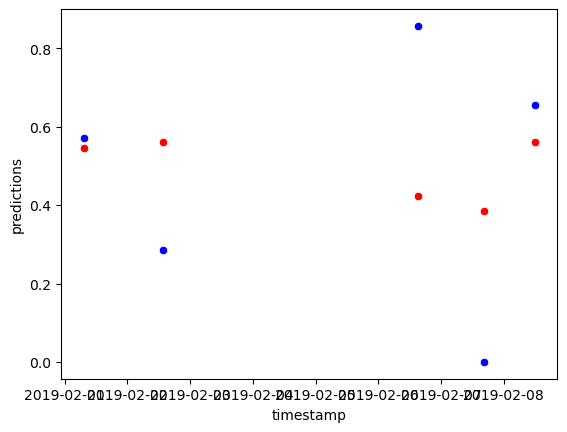

In [37]:
val_dataset['predictions'] = y_val_pred

timeframe_graphed = (val_dataset['timestamp'] >= dt(2019,2,1, tzinfo = timezone.utc)) & (val_dataset['timestamp'] < dt(2019,2,14, tzinfo = timezone.utc))

sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == '5575.08') & timeframe_graphed], x='timestamp', y='predictions', color = 'red')

sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == '5575.08') & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')
# sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == '5532.01') & timeframe_graphed], x='timestamp', y='predictions', color = 'blue')


### Model Perforamnce logs

In [26]:

model_logs = pd.read_csv('model_logs.csv')
model_logs.loc[len(model_logs)] = pd.Series({
    'model_name': 'used dataset with 500,000 rows by per csv',
    'train_mae': val_mae,
    'train_rmse': val_rmse,
    'R^2': val_r2,
    'hyperparams': 'default',
    'features_used': 'Standard',
    'notes': 'holy shit more data actually matters so much'
})

model_logs.to_csv('model_logs.csv', index=False)

In [29]:
model_logs = pd.read_csv('model_logs.csv')
pd.set_option('display.max_colwidth', None)
model_logs

,model_name,train_mae,train_rmse,R^2,hyperparams,features_used,notes
0,Baseline CatBoost,0.143460,0.187209,0.624322,default,"NO lag features, baseline","Default parameters, seems kinda weak, ran on medium sized dataset with just sparse data from the first 2 csvs"
1,Cat Boost with first before time stamp lag,0.019427,0.044316,0.978949,default,Only lag from previous measurement and time since last measurement,"Pretty good but I feel like the predictive power is limited since the lags are so close, will have to figure out better lag design"
2,Standard with more data and from 2017 and 2018,0.163594,0.210014,0.515280,"default, will change to 500 iteration since conversion seems to be at around 200",Standard,uhhh i feel like more data had a very marginal improvement
3,Standard with more data and from 2017 and 2018,0.215938,0.277457,0.243575,default,Standard,oops will start logging test results from now on
4,"Standard using only stations in Manhatten under 14th st. Used 2017 to 2018 data with 100,000 cols per csv, used 10,000 per csv for cross val",0.202173,0.256919,0.419616,default,"Standard, added volitatity",lowkey using used stations make big difference
5,"same as previous but I took out volitatiy, turned out to be bad i guess",0.200971,0.255792,0.424698,default,Standard,lowkey using used stations make big difference
6,added minute feature,0.201037,0.255623,0.425459,default,Standard + minute,literally no difference i guess will keep in the model
7,changed max iterations to 1000,0.197427,0.253156,0.436494,default,Standard,"lowkey max iterations makes a gud difference, model is still underfitting and could be better with more"
8,"used dataset with 500,000 rows by per csv",0.173122,0.217899,0.582525,default,Standard,holy shit more data actually matters so much


In [118]:

val_dataset['predictions'] = y_val_pred
val_dataset['station_name'] = val_dataset['shortname'].map(used_shortname_to_name)

# 2. Define a small helper function to calculate MAE
def calculate_station_mae(group):
    # 'percentage_available' is your actual target
    return mean_absolute_error(group['percentage_available'], group['predictions'])

# 3. Group by station and apply the function
station_errors = val_dataset.groupby('station_name').apply(calculate_station_mae)

# 4. Convert to a clean, sorted DataFrame for easy reading
station_errors_df = station_errors.reset_index()
station_errors_df.columns = ['station_name', 'MAE']
station_errors_df = station_errors_df.sort_values(by='MAE', ascending=False)

# 5. Print the results
print("--- MAE per Individual Station ---")
print(station_errors_df)

/tmp/ipykernel_94434/3767972057.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  station_errors = val_dataset.groupby('station_name').apply(calculate_station_mae)


--- MAE per Individual Station ---
                      station_name       MAE
4              Court St & State St  0.311727
9              Park Pl & Church St  0.292149
12                 W 13 St & 7 Ave  0.287168
7            Lorimer St & Broadway  0.283180
2            Clinton St & Union St  0.252759
1                     2 Ave & 9 St  0.245809
11  Greenpoint Ave & Manhattan Ave  0.243156
3                  Dean St & 4 Ave  0.241901
5          South St & Whitehall St  0.239801
8             Centre St & Worth St  0.225113
6            Broadway & Battery Pl  0.223182
16                  36 Ave & 10 St  0.221969
25                   Montgomery St  0.217086
17                  35 Ave & 10 St  0.216754
10           Mercer St & Spring St  0.198034
19    Central Park West & W 100 St  0.194256
21                Marin Light Rail  0.190670
15                  21 St & 36 Ave  0.186954
24         Communipaw & Berry Lane  0.184839
0              Garfield Pl & 8 Ave  0.183792
14                 E

/tmp/ipykernel_94434/3767972057.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  station_errors = val_dataset.groupby('station_name').apply(calculate_station_mae)


### Time Series Cross Validation Setup

In [ ]:
df_full = process_file('train_set.csv')
feature_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'prev_percentage', 'time_since_last_lag', 'IsRushHour']
X = df_full[feature_columns]
y = df_full['percentage_available']

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)

# Store results for each fold
cv_results = {
    'fold': [],
    'train_mae': [],
    'train_rmse': [],
    'train_r2': [],
    'val_mae': [],
    'val_rmse': [],
    'val_r2': []
}

# Perform cross-validation
for fold_idx, (train_idx, val_idx) in enumerate(tscv.split(X), 1):
    print(f"\nFold {fold_idx}:")
    print(f"  Train size: {len(train_idx)}, Validation size: {len(val_idx)}")
    
    # Split data for this fold
    X_train_fold = X.iloc[train_idx]
    X_val_fold = X.iloc[val_idx]
    y_train_fold = y.iloc[train_idx]
    y_val_fold = y.iloc[val_idx]
    
    # Train model
    model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.1,
        depth=6,
        loss_function='RMSE',
        eval_metric='RMSE',
        random_seed=42,
        verbose=100
        
    )
    model.fit(X_train_fold, y_train_fold)
    
    # Predictions
    y_train_pred_fold = model.predict(X_train_fold)
    y_val_pred_fold = model.predict(X_val_fold)
    
    # Calculate metrics
    train_mae_fold = mean_absolute_error(y_train_fold, y_train_pred_fold)
    train_rmse_fold = np.sqrt(mean_squared_error(y_train_fold, y_train_pred_fold))
    train_r2_fold = r2_score(y_train_fold, y_train_pred_fold)
    
    val_mae_fold = mean_absolute_error(y_val_fold, y_val_pred_fold)
    val_rmse_fold = np.sqrt(mean_squared_error(y_val_fold, y_val_pred_fold))
    val_r2_fold = r2_score(y_val_fold, y_val_pred_fold)
    
    # Store results
    cv_results['fold'].append(fold_idx)
    cv_results['train_mae'].append(train_mae_fold)
    cv_results['train_rmse'].append(train_rmse_fold)
    cv_results['train_r2'].append(train_r2_fold)
    cv_results['val_mae'].append(val_mae_fold)
    cv_results['val_rmse'].append(val_rmse_fold)
    cv_results['val_r2'].append(val_r2_fold)
    
    print(f"  Validation MAE:  {val_mae_fold:.4f}")
    print(f"  Validation RMSE: {val_rmse_fold:.4f}")
    print(f"  Validation R²:   {val_r2_fold:.4f}")

# Calculate average metrics across all folds
print("\n" + "="*50)
print("Cross-Validation Summary")
print("="*50)
print(f"\nAverage Training Metrics:")
print(f"  MAE:  {np.mean(cv_results['train_mae']):.4f} (+/- {np.std(cv_results['train_mae']):.4f})")
print(f"  RMSE: {np.mean(cv_results['train_rmse']):.4f} (+/- {np.std(cv_results['train_rmse']):.4f})")
print(f"  R²:   {np.mean(cv_results['train_r2']):.4f} (+/- {np.std(cv_results['train_r2']):.4f})")

print(f"\nAverage Validation Metrics:")
print(f"  MAE:  {np.mean(cv_results['val_mae']):.4f} (+/- {np.std(cv_results['val_mae']):.4f})")
print(f"  RMSE: {np.mean(cv_results['val_rmse']):.4f} (+/- {np.std(cv_results['val_rmse']):.4f})")
print(f"  R²:   {np.mean(cv_results['val_r2']):.4f} (+/- {np.std(cv_results['val_r2']):.4f})")